In [1]:
import os
import random
import time
# %pip install "gymnasium[classic-control]"
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as opt
from torch.distributions import Categorical

In [ ]:
# %%
# settings
env_id = "CartPole-v1"

# number of environments to run in parallel
num_envs = 4

# total number of timesteps for training over multiple episodes
total_timesteps = 100_000

# adam learning rate
learning_rate = 8e-4

# discount factor
gamma = 0.99

# seed for reproducibility
seed = None

#A2C settings

#entropy coefficient for the loss function
entropy_weight = 0.01

#value coefficient for the loss function
value_weight = 0.25

# max L2 norm for gradient clipping
# control the magnitude of the gradient that we use for the update.
# set the maximum norm for the gradient vector
max_norm = 0.5

video_path = "a2c_cartpole_videos"

device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "cpu"
)

In [4]:
def make_env(env_id, capture_video, seed=None):
    if capture_video:
        env = gym.make(env_id, render_mode="rgb_array")
        env = gym.wrappers.RecordVideo(env, video_path, episode_trigger=lambda episode: True) # ensure that recofrds all episodes
    else:
        env = gym.make(env_id)

    env = gym.wrappers.RecordEpisodeStatistics(env)

    if seed is not None:
        env.action_space.seed(seed)

    return env

In [12]:
# NN
class ActorCritic(nn.Module):

    def __init__(self, envs, n_hidden=128):
        super().__init__()

        self.network = nn.Sequential(
                        nn.Linear(envs.single_observation_space.shape[0], n_hidden),
                        nn.ReLU(),
        )

        #2 heads: one for the policy (actor) and one for the value function (critic)

        # Actor / Policy head: outputs the action probabilities for each action in the action space
        # this will give us logits for each action, which we can then convert to probabilities using a softmax function
        self.actor = nn.Linear(n_hidden, envs.single_action_space.n)

        # Critic / Value head: outputs the estimated value of the current state
        self.critic = nn.Linear(n_hidden, 1)

    def forward(self, x):
        x = self.network(x)
        return self.actor(x), self.critic(x)

def np2torch(a, to_float=True):
    if to_float:
        dtype = torch.float32
    else:
        dtype = torch.int64

    return torch.as_tensor(a, dtype=dtype, device=device)

# sample an action from the policy network logits
def sample_action(logits):
    distribution = Categorical(logits=logits)
    action = distribution.sample()
    return action

# compute entropy for loss regularization
def compute_entropy(policy_logits):
    probs = F.softmax(policy_logits, dim=-1) # convert logits to probabilities
    log_probs = F.log_softmax(policy_logits, dim=-1) # compute log probabilities
    entropy = -(probs * log_probs).sum(dim=-1) # compute entropy for each sample in the batch
    return entropy.mean(), log_probs # take the mean entropy across the batch and return log probabilities for each sample

# compute entropy for loss regularization
def compute_entropy_and_log_prob(logits, actions):
    distribution = Categorical(logits=logits)
    return distribution.entropy().mean(), distribution.log_prob(actions)

In [6]:
# make environaments
envs = gym.vector.SyncVectorEnv(
    [
        lambda i=i: make_env(
            env_id,
            False,
            seed=None if seed is None else seed + i,
        )
        for i in range(num_envs)
    ]
)

In [15]:
episode_returns = []
losses = []
current_state_obs, _ = envs.reset(seed=seed) # States [B, 4] [B=1, [Cart position, Cart velocity, Pole angle, Pole angular velocity]]
auto_reset = np.zeros(num_envs, dtype = bool)

# Online AC-Network
ac_network = ActorCritic(envs).to(device) # state --> NN --> Q(s,a), where predicted_value = Q(s,a).max() and predicted_action = arg_max(Q(s,a))
optimizer = opt.Adam(ac_network.parameters(), lr=learning_rate)

start_time = time.time()

for global_step in range(total_timesteps):
    
    # sample an action from the policy network logits
    action_logits, values = ac_network(np2torch(current_state_obs))

    # select actions based on the logits from the policy network
    actions = sample_action(action_logits)
    action_np = actions.detach().cpu().numpy()

    # take a step in the environment using the selected actions
    next_state_obs, rewards, terminateds, truncateds, infos = envs.step(action_np)

    # store episode returns for plotting
    for i, (terminated, truncated) in enumerate(zip(terminateds, truncateds)):
        if terminated or truncated:
            ret = infos['episode']['r'][i]
            episode_returns.append(ret)
            print(f"global_step={global_step}, episode={len(episode_returns)}, episode_return={ret}, time={time.time() - start_time:.2f}s")

    # training
    mask = np.logical_not(auto_reset) # [B] bool, from the PREVIOUS iteration
    auto_reset = np.logical_or(terminateds, truncateds) # store for the NEXT iteration

    # note: if autoreset is true, next_state_obs will be s(1) for the next episode, otherwise it will be s(t+1) for the current episode
    #  we want all the states that we use in our computation to be from the same episode 
    if not mask.any():
        current_state_obs = next_state_obs
        continue    

    # apply mask to rewards and next_state_obs to ignore the transitions that are from the next episode
    values_masked = values[mask]
    current_state_obs_masked = current_state_obs[mask]
    actions_masked = actions[mask]
    action_logits_masked = action_logits[mask]
    rewards_masked = rewards[mask]
    next_state_obs_masked = next_state_obs[mask]
    terminateds_masked = terminateds[mask]

    # compute each of the components of the loss one by one.

    # value loss, actor
    with torch.no_grad():
        next_values = ac_network(np2torch(next_state_obs_masked))[1] # actor logits per action, value for the next state
        td_target = np2torch(rewards_masked.flatten()) + gamma * next_values.flatten() * (1 - np2torch(terminateds_masked.flatten()))

     # compute the critic loss (value function loss)
    pred_values = values_masked.squeeze(-1)
    critic_value_loss = F.mse_loss(pred_values, td_target)

    # compute the actor loss (policy gradient loss), use 1 step TD error
    entropy, log_probs = compute_entropy(action_logits_masked)
    advantages = td_target - values_masked.squeeze(-1)
    selected_log_probs = log_probs.gather(1, actions_masked.unsqueeze(-1)).squeeze(-1) # get the log probs for the selected actions - log_probs[:, actions_masked]
    actor_policy_loss = -(selected_log_probs * advantages.detach()).mean() # detach the advantages to avoid backpropagating through the value network when computing the actor loss

    # total loss
    # as entropy is something we want to maximize, we subtract it from the loss function.
    total_loss = actor_policy_loss - entropy_weight * entropy + value_weight * critic_value_loss
    losses.append(total_loss.item())

    if global_step % 100 == 0:
        print(f"steps per second: {global_step / (time.time() - start_time):.2f}, global_step={global_step}, total_loss={total_loss.item():.4f}, actor_loss={actor_policy_loss.item():.4f}, critic_loss={critic_value_loss.item():.4f}, entropy={entropy.item():.4f}")

    # Update model
    optimizer.zero_grad()
    total_loss.backward()
    # nn.utils.clip_grad_norm_(ac_network.parameters(), max_norm) # optional: clip gradients to avoid exploding gradients
    optimizer.step()

    current_state_obs = next_state_obs

    # let's break if the last 10 episode returns had the maximum return of 500, which is the maximum return for CartPole-v1
    if len(episode_returns) >= 10 and all(ret == 500 for ret in episode_returns[-10:]):
        print(f"Max reward achieved! Solved in {global_step} steps!")
        break

steps per second: 0.00, global_step=0, total_loss=0.7866, actor_loss=0.5538, critic_loss=0.9584, entropy=0.6839
global_step=12, episode=1, episode_return=13.0, time=0.13s
global_step=21, episode=2, episode_return=22.0, time=0.18s
global_step=31, episode=3, episode_return=18.0, time=0.23s
global_step=34, episode=4, episode_return=12.0, time=0.24s
global_step=42, episode=5, episode_return=10.0, time=0.29s
global_step=61, episode=6, episode_return=26.0, time=0.37s
global_step=66, episode=7, episode_return=67.0, time=0.39s
global_step=66, episode=8, episode_return=23.0, time=0.39s
global_step=73, episode=9, episode_return=74.0, time=0.42s
global_step=75, episode=10, episode_return=13.0, time=0.43s
global_step=87, episode=11, episode_return=20.0, time=0.49s
global_step=87, episode=12, episode_return=20.0, time=0.49s
global_step=92, episode=13, episode_return=18.0, time=0.51s
global_step=96, episode=14, episode_return=20.0, time=0.53s
steps per second: 182.37, global_step=100, total_loss=1.0

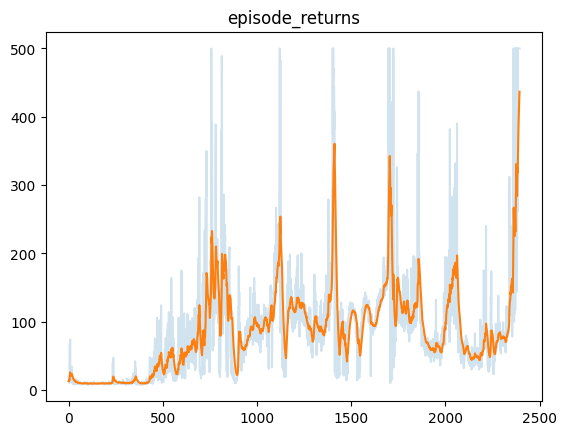

In [16]:
def smooth(x, a=0.1):
    y = [x[0]]
    for xi in x[1:]:
        yi = a * xi + (1-a) * y[-1]
        y.append(yi)
    return y

plt.plot(episode_returns, alpha=0.2)
plt.plot(smooth(episode_returns))
plt.title("episode_returns")
plt.show()

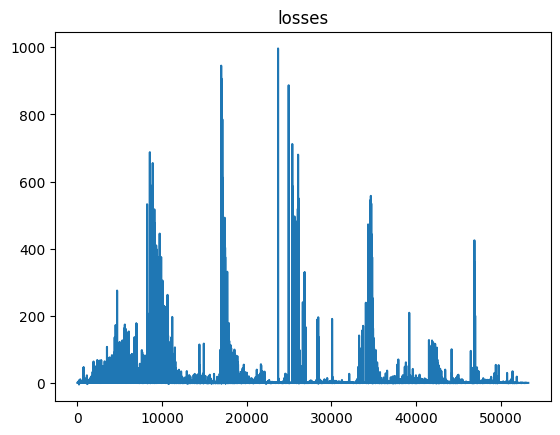

In [17]:
plt.plot(losses)
plt.title("losses")
plt.show()

In [18]:
# save model
model_path = "/workspace/repos/jupyter_notebooks/Reinforcement_Learning/A2C_1.pth"
torch.save(ac_network.state_dict(), model_path)

In [19]:
# load the model for eval
# %pip install "gymnasium[other]"
envs_eval = gym.vector.SyncVectorEnv([lambda: make_env(env_id, True)]) # open with recording
model = ActorCritic(envs_eval).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()


ActorCritic(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
  )
  (actor): Linear(in_features=128, out_features=2, bias=True)
  (critic): Linear(in_features=128, out_features=1, bias=True)
)

In [20]:
# evaluate the model
n_episodes_eval = 3
eval_returns = np.zeros(n_episodes_eval)
state_obs, _ = envs_eval.reset(seed=500)
 
for i in range(n_episodes_eval):
    episode_done = False
 
    while not episode_done:
        # [FIX-4] the network returns (z_θ(s), V_φ(s)), not Q-values. Greedy evaluation takes the mode
        # of the policy: a = argmax_a π_θ(a|s) = argmax_a z_θ(s)_a  (softmax is monotonic).
        # torch.no_grad(): inference only, so no graph is recorded.
        with torch.no_grad():
            action_logits, _ = model(np2torch(state_obs))
        actions = torch.argmax(action_logits, dim=1).cpu().numpy()
        # (from the 2nd episode on, the first step() call is the NEXT_STEP reset step; its action is ignored)
        state_obs, rewards, terminateds, truncateds, infos = envs_eval.step(actions)
 
        if terminateds[0] or truncateds[0]:
            G = infos['episode']['r'][0]
            print(f"episode: {i}, return= {G}")
            eval_returns[i] = G
            episode_done = True

envs_eval.close()

episode: 0, return= 500.0
episode: 1, return= 500.0
episode: 2, return= 500.0


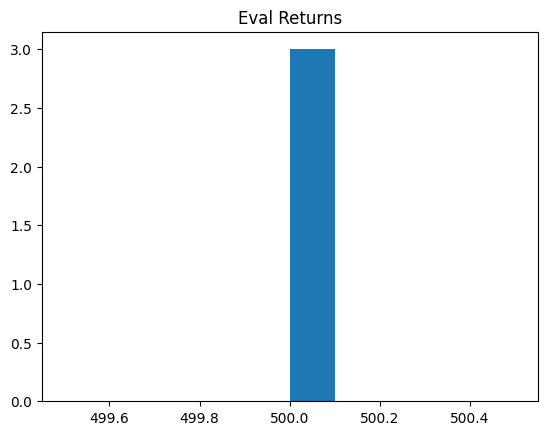

In [21]:
plt.hist(eval_returns)
plt.title("Eval Returns")
plt.show();

In [22]:
# prompt display video in notebook
from IPython.display import HTML
from base64 import b64encode

mp4 = open(f'{video_path}/rl-video-episode-2.mp4', 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML("""
<video width=400 controls>
    <source src="%s" type="video/mp4">
</video>
""" % data_url)